# Analisis Data: Perbandingan Performa dan CPU Overhead Web Server HTTP/2 vs HTTP/3 (QUIC)

**Proyek:** Analisis Perbandingan Performa dan CPU Overhead Web Server QUIC (HTTP/3) dan HTTP/2 pada Jaringan Internal Kampus Politeknik Caltex Riau
**Mata kuliah:** Probabilitas dan Statistika, 3TIC, Kelompok 4

Notebook ini adalah kode di balik **Bab 4 (Hasil dan Pembahasan)**. Urutan bagiannya sengaja disamakan dengan Bab 4 di laporan:

| Bagian notebook | Bagian laporan | Keluaran |
|---|---|---|
| 1 | 4.1 Pemeriksaan data | Tabel 4.1 |
| 2 | 4.2 Statistika deskriptif | Tabel 4.2 sampai 4.4, Gambar 4.1 sampai 4.4 |
| 3 | 4.3 Uji normalitas | Tabel 4.5, Gambar 4.5 |
| 4 | 4.4 Uji beda dua kelompok | Tabel 4.6 |
| 5 | 4.5 Besar dan arah selisih | Tabel 4.7 |
| 6 | 4.6 Analisis pendukung pembahasan | Tabel 4.8 sampai 4.9, Gambar 4.6 sampai 4.7 |

**Cara menjalankan (Google Colab):** unggah berkas `3TIC_04_PerformaQUICvsHTTP2.xlsx` ke Colab (ikon folder di kiri), lalu pilih *Runtime > Run all*. Bila berkas belum diunggah, sel pemuatan data akan menampilkan tombol unggah. Semua tabel disimpan ke folder `tabel/` (CSV) dan semua gambar ke folder `gambar/` (PNG).

**Catatan penting tentang aturan analisis.** Aturan keputusan (median dan IQR sebagai ukuran utama, uji Shapiro-Wilk lalu Welch atau Mann-Whitney U, koreksi Holm, Cohen's d atau Cliff's delta, bootstrap 95%) mengikuti Bab 3.9 dan **ditetapkan sebelum hasilnya dilihat**. Kode di bawah memilih uji secara otomatis dari hasil Shapiro-Wilk, bukan dari selera.

## 0. Persiapan

In [1]:
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy import stats

warnings.filterwarnings("ignore")
os.makedirs("gambar", exist_ok=True)
os.makedirs("tabel", exist_ok=True)

# ---- Parameter yang ditetapkan di awal (Bab 3.9) ----
ALPHA      = 0.05          # taraf signifikansi, dua arah
N_BOOT     = 10000         # jumlah resampling bootstrap
SEED       = 20261003      # biar hasil bootstrap bisa diulang persis
BYTES_FILE = 10_485_760    # ukuran berkas uji (10 MiB)
rng = np.random.default_rng(SEED)

VARS = {                    # nama kolom -> (label, satuan)
    "throughput":    ("Throughput", "Mbps"),
    "waktu_respons": ("Waktu respons (TTFB)", "ms"),
    "cpu_persen":    ("Penggunaan CPU server", "% dari satu core"),
}
PROTO = ["HTTP/2", "HTTP/3"]
WARNA = {"HTTP/2": "#0072B2", "HTTP/3": "#E69F00"}   # biru dan oranye, aman untuk buta warna

# Gaya grafik: serif supaya senada dengan laporan (Times New Roman); kalau tidak ada, matplotlib pakai serif lain
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Liberation Serif", "DejaVu Serif"],
    "font.size": 10, "axes.titlesize": 11, "axes.labelsize": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.dpi": 110, "savefig.dpi": 220, "savefig.bbox": "tight",
})

# Koreksi Holm (step-down)
def holm(pvals):
    p = np.asarray(pvals, float); n = len(p); order = np.argsort(p); adj = np.empty(n); running = 0
    for rank, idx in enumerate(order):
        running = max(running, (n - rank) * p[idx]); adj[idx] = min(1, running)
    return adj

def simpan(fig, nama):
    fig.savefig(f"gambar/{nama}.png"); plt.show()

def fmt(x, d=3):
    return f"{x:,.{d}f}"

## 1. Pemuatan dan pemeriksaan data (Bab 4.1, Tabel 4.1)

Data dibaca dari sheet **Data**. Nama kolom adalah nama final dan tidak boleh diubah.

In [2]:
NAMA_BERKAS = "3TIC_04_PerformaQUICvsHTTP2.xlsx"
if not os.path.exists(NAMA_BERKAS):
    try:
        from google.colab import files          # hanya jalan di Colab
        print("Unggah berkas", NAMA_BERKAS)
        up = files.upload()
        NAMA_BERKAS = list(up.keys())[0]
    except ImportError:
        raise FileNotFoundError(f"Taruh {NAMA_BERKAS} di folder yang sama dengan notebook ini.")

df = pd.read_excel(NAMA_BERKAS, sheet_name="Data")
df = df.sort_values("id_run").reset_index(drop=True)
print(df.shape)
df.head()

(200, 7)


,id_run,protokol,timestamp,status_run,throughput,waktu_respons,cpu_persen
0,1,HTTP/2,2026-10-03 17:38:15,ok,55.854,63.899,0.891
1,2,HTTP/3,2026-10-03 17:38:17,ok,513.558,43.238,22.738
2,3,HTTP/2,2026-10-03 17:38:17,ok,50.415,63.501,0.703
3,4,HTTP/3,2026-10-03 17:38:20,ok,515.844,43.774,23.008
4,5,HTTP/3,2026-10-03 17:38:20,ok,516.880,43.831,23.356


In [3]:
# ---- Pemeriksaan struktur dan kualitas ----
print("Kolom           :", list(df.columns))
print("Tipe data       :"); print(df.dtypes.to_string()); print()
print("Nilai kosong    :"); print(df.isna().sum().to_string()); print()
print("Jumlah per protokol:"); print(df["protokol"].value_counts().to_string()); print()
print("Status run      :"); print(df["status_run"].value_counts().to_string()); print()
print("id_run unik dan berurutan 1..200 :", df["id_run"].is_unique and (df["id_run"].tolist() == list(range(1, len(df)+1))))
print("timestamp tidak mundur           :", df["timestamp"].is_monotonic_increasing)
print("Rentang waktu    :", df["timestamp"].min(), "sampai", df["timestamp"].max())
print("Semua nilai ukur positif         :", bool((df[list(VARS)] > 0).all().all()))

# Urutan protokol diacak per pasangan: seberapa sering protokol sama berurutan?
df["prev_protokol"] = df["protokol"].shift(1)
print()
print("Tabel silang protokol sebelumnya vs sekarang (cek pengacakan):")
print(pd.crosstab(df["prev_protokol"], df["protokol"]).to_string())

Kolom           : ['id_run', 'protokol', 'timestamp', 'status_run', 'throughput', 'waktu_respons', 'cpu_persen']
Tipe data       :
id_run                    int64
protokol                    str
timestamp        datetime64[us]
status_run                  str
throughput              float64
waktu_respons           float64
cpu_persen              float64

Nilai kosong    :
id_run           0
protokol         0
timestamp        0
status_run       0
throughput       0
waktu_respons    0
cpu_persen       0

Jumlah per protokol:
protokol
HTTP/2    100
HTTP/3    100

Status run      :
status_run
ok    200

id_run unik dan berurutan 1..200 : True
timestamp tidak mundur           : True
Rentang waktu    : 2026-10-03 17:38:15 sampai 2026-10-03 17:42:02
Semua nilai ukur positif         : True

Tabel silang protokol sebelumnya vs sekarang (cek pengacakan):
protokol       HTTP/2  HTTP/3
prev_protokol                
HTTP/2             25      75
HTTP/3             74      25


In [4]:
# ---- Pencilan 1,5 x IQR per variabel per protokol (Bab 3.9.1) ----
def batas_iqr(x):
    q1, q3 = np.percentile(x, [25, 75]); iqr = q3 - q1
    return q1 - 1.5*iqr, q3 + 1.5*iqr

df["pencilan_throughput"] = False; df["pencilan_waktu_respons"] = False; df["pencilan_cpu_persen"] = False
pencilan = {}
for v in VARS:
    for p in PROTO:
        m = df["protokol"] == p
        lo, hi = batas_iqr(df.loc[m, v])
        flag = m & ((df[v] < lo) | (df[v] > hi))
        df.loc[flag, f"pencilan_{v}"] = True
        pencilan[(v, p)] = (int(flag.sum()), lo, hi)

tabel41 = pd.DataFrame({
    "Pemeriksaan": ["Jumlah baris data utama", "Run berstatus ok", "Run berstatus gagal", "Nilai kosong",
                    "Run pemanasan dibuang",
                    "Pencilan 1,5 x IQR: throughput", "Pencilan 1,5 x IQR: TTFB", "Pencilan 1,5 x IQR: CPU"]})
for p in PROTO:
    g = df[df["protokol"] == p]
    tabel41[p] = [len(g), int((g["status_run"] == "ok").sum()), int((g["status_run"] != "ok").sum()),
                  int(g[list(VARS)].isna().sum().sum()), 10,
                  pencilan[("throughput", p)][0], pencilan[("waktu_respons", p)][0], pencilan[("cpu_persen", p)][0]]
tabel41.to_csv("tabel/tabel_4_1_pemeriksaan_data.csv", index=False)
tabel41

,Pemeriksaan,HTTP/2,HTTP/3
0,Jumlah baris data utama,100,100
1,Run berstatus ok,100,100
2,Run berstatus gagal,0,0
3,Nilai kosong,0,0
4,Run pemanasan dibuang,10,10
5,"Pencilan 1,5 x IQR: throughput",1,14
6,"Pencilan 1,5 x IQR: TTFB",0,16
7,"Pencilan 1,5 x IQR: CPU",1,7


In [5]:
# Batas pencilan yang dipakai (untuk dicantumkan di laporan)
pd.DataFrame([(v, p, n, round(lo, 3), round(hi, 3)) for (v, p), (n, lo, hi) in pencilan.items()],
             columns=["variabel", "protokol", "n_pencilan", "batas_bawah", "batas_atas"])

,variabel,protokol,n_pencilan,batas_bawah,batas_atas
0,throughput,HTTP/2,1,-117.974,358.266
1,throughput,HTTP/3,14,510.996,519.741
2,waktu_respons,HTTP/2,0,61.984,65.228
3,waktu_respons,HTTP/3,16,43.156,44.442
4,cpu_persen,HTTP/2,1,-1.395,4.859
5,cpu_persen,HTTP/3,7,19.818,24.941


## 2. Statistika deskriptif (Bab 4.2, Tabel 4.2 sampai 4.4)

Karena sebaran throughput lebar, **median dan IQR** adalah ukuran utama. Rata-rata dan simpangan baku hanya pelengkap. Simpangan baku memakai `ddof=1` (simpangan baku sampel). Kuartil memakai metode linear bawaan NumPy.

In [6]:
def deskriptif(x):
    q1, med, q3 = np.percentile(x, [25, 50, 75])
    return {"Jumlah pengamatan (n)": len(x), "Rata-rata": np.mean(x), "Median": med,
            "Simpangan baku": np.std(x, ddof=1), "Minimum": np.min(x), "Maksimum": np.max(x),
            "Kuartil pertama (Q1)": q1, "Kuartil ketiga (Q3)": q3, "Rentang antar kuartil (IQR)": q3 - q1}

NO_TABEL = {"throughput": "4_2", "waktu_respons": "4_3", "cpu_persen": "4_4"}
desk = {}
for v, (lab, sat) in VARS.items():
    t = pd.DataFrame({p: deskriptif(df.loc[df["protokol"] == p, v].to_numpy()) for p in PROTO})
    desk[v] = t
    t.to_csv(f"tabel/tabel_{NO_TABEL[v]}_deskriptif_{v}.csv")
    print(f"--- {lab} ({sat}) ---")
    display(t.round(3))

--- Throughput (Mbps) ---


,HTTP/2,HTTP/3
Jumlah pengamatan (n),100.000,100.000
Rata-rata,126.898,510.141
Median,79.493,515.637
Simpangan baku,87.114,14.874
Minimum,36.163,450.306
Maksimum,413.786,518.407
Kuartil pertama (Q1),60.616,514.275
Kuartil ketiga (Q3),179.676,516.462
Rentang antar kuartil (IQR),119.060,2.186


--- Waktu respons (TTFB) (ms) ---


,HTTP/2,HTTP/3
Jumlah pengamatan (n),100.000,100.000
Rata-rata,63.600,43.833
Median,63.518,43.774
Simpangan baku,0.555,0.499
Minimum,62.332,42.825
Maksimum,64.969,45.793
Kuartil pertama (Q1),63.200,43.638
Kuartil ketiga (Q3),64.011,43.960
Rentang antar kuartil (IQR),0.811,0.322


--- Penggunaan CPU server (% dari satu core) ---


,HTTP/2,HTTP/3
Jumlah pengamatan (n),100.000,100.000
Rata-rata,1.822,22.538
Median,1.220,22.382
Simpangan baku,1.155,1.718
Minimum,0.513,19.235
Maksimum,5.634,29.974
Kuartil pertama (Q1),0.950,21.740
Kuartil ketiga (Q3),2.514,23.020
Rentang antar kuartil (IQR),1.564,1.281


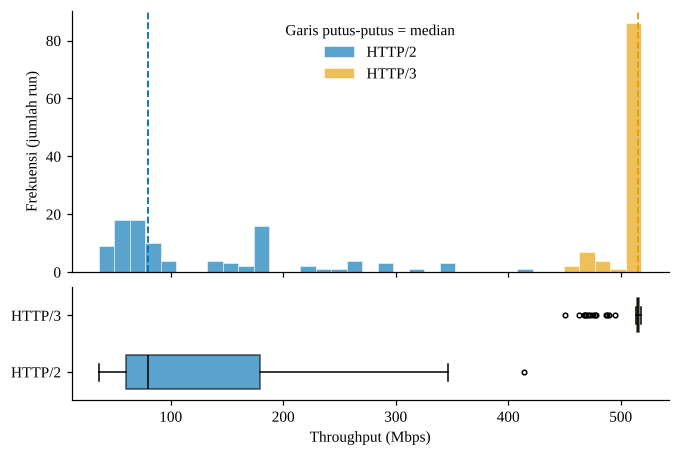

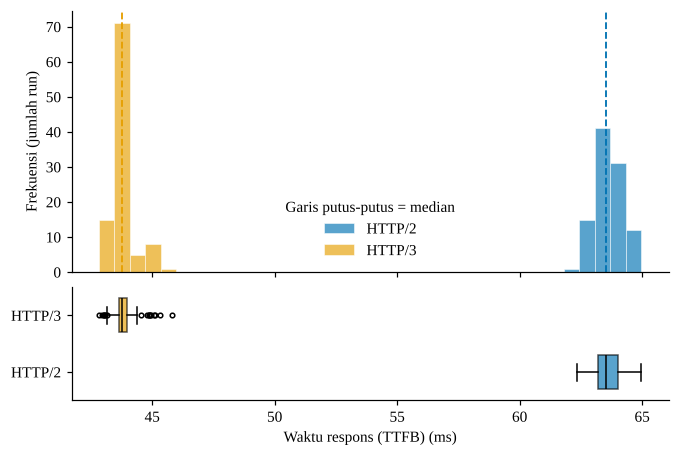

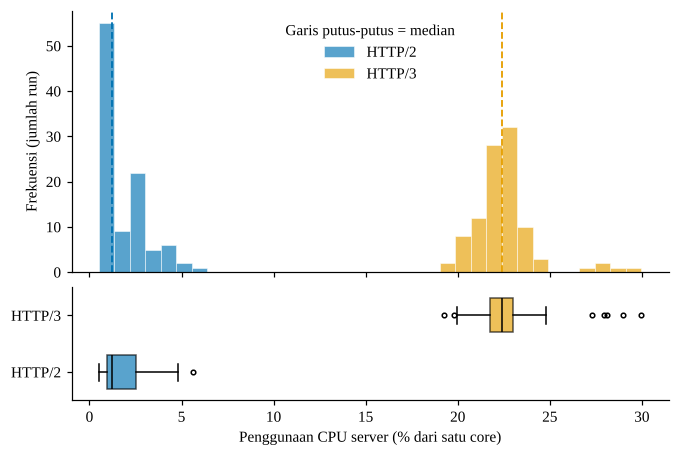

In [7]:
# ---- Gambar 4.1 sampai 4.3: histogram + boxplot per variabel ----
NO_GAMBAR = {"throughput": "4_1", "waktu_respons": "4_2", "cpu_persen": "4_3"}
for v, (lab, sat) in VARS.items():
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(7, 4.6), sharex=True,
                                   gridspec_kw={"height_ratios": [3, 1.3], "hspace": 0.08})
    bins = np.histogram_bin_edges(df[v], bins=35)
    for p in PROTO:
        ax1.hist(df.loc[df["protokol"] == p, v], bins=bins, alpha=0.65, color=WARNA[p],
                 label=p, edgecolor="white", linewidth=0.5)
        med = df.loc[df["protokol"] == p, v].median()
        ax1.axvline(med, color=WARNA[p], ls="--", lw=1.2)
    ax1.set_ylabel("Frekuensi (jumlah run)")
    ax1.legend(frameon=False, title="Garis putus-putus = median")
    data_box = [df.loc[df["protokol"] == p, v] for p in PROTO]
    bp = ax2.boxplot(data_box, vert=False, widths=0.6, patch_artist=True, showfliers=True,
                     flierprops=dict(marker="o", markersize=3, markerfacecolor="none"),
                     medianprops=dict(color="black"))
    for patch, p in zip(bp["boxes"], PROTO):
        patch.set_facecolor(WARNA[p]); patch.set_alpha(0.65)
    ax2.set_yticklabels(PROTO); ax2.set_xlabel(f"{lab} ({sat})")
    simpan(fig, f"gambar_{NO_GAMBAR[v]}_sebaran_{v}")

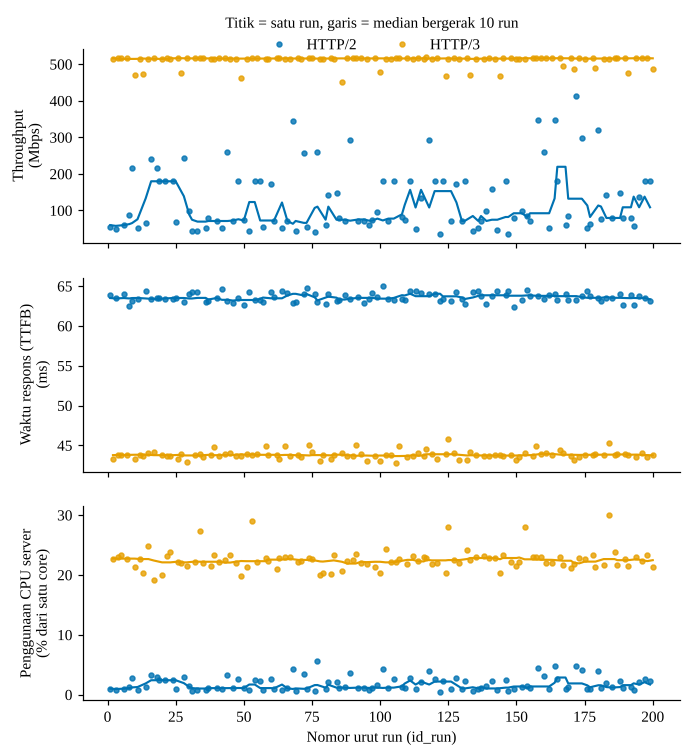

,Variabel,Protokol,rho Spearman,nilai-p
0,Throughput,HTTP/2,0.122,0.225
1,Throughput,HTTP/3,0.071,0.482
2,Waktu respons (TTFB),HTTP/2,0.044,0.667
3,Waktu respons (TTFB),HTTP/3,0.053,0.599
4,Penggunaan CPU server,HTTP/2,0.116,0.249
5,Penggunaan CPU server,HTTP/3,0.061,0.547


In [8]:
# ---- Gambar 4.4: plot urutan run (apakah nilai bergeser sepanjang sesi?) ----
fig, axs = plt.subplots(3, 1, figsize=(7, 7.5), sharex=True, gridspec_kw={"hspace": 0.18})
for ax, (v, (lab, sat)) in zip(axs, VARS.items()):
    for p in PROTO:
        g = df[df["protokol"] == p]
        ax.plot(g["id_run"], g[v], "o", ms=3.2, color=WARNA[p], alpha=0.8, label=p)
        ax.plot(g["id_run"], g[v].rolling(10, center=True, min_periods=5).median(), "-", lw=1.4, color=WARNA[p])
    ax.set_ylabel(f"{lab}\n({sat})")
h, l = axs[0].get_legend_handles_labels()
fig.legend(h, l, loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 0.955),
           title="Titik = satu run, garis = median bergerak 10 run")
fig.subplots_adjust(top=0.9)
axs[-1].set_xlabel("Nomor urut run (id_run)")
simpan(fig, "gambar_4_4_urutan_run")

# ---- Uji kecenderungan terhadap urutan run (Spearman), per variabel per protokol ----
rows = []
for v, (lab, sat) in VARS.items():
    for p in PROTO:
        g = df[df["protokol"] == p]
        r = stats.spearmanr(g["id_run"], g[v])
        rows.append((lab, p, r.statistic, r.pvalue))
trend = pd.DataFrame(rows, columns=["Variabel", "Protokol", "rho Spearman", "nilai-p"])
trend.to_csv("tabel/pendukung_kecenderungan_urutan_run.csv", index=False)
trend.round(3)

In [9]:
# ---- Autokorelasi lag-1: apakah sebuah run mirip dengan run sebelumnya dari protokol yang sama? ----
# Uji permutasi (3000 kali): bandingkan rho lag-1 teramati dengan rho dari urutan yang diacak.
rows = []
for v, (lab, sat) in VARS.items():
    for p in PROTO:
        x = df.loc[df["protokol"] == p, v].to_numpy()
        r = stats.spearmanr(x[:-1], x[1:]).statistic
        perm = np.array([stats.spearmanr(*(lambda y: (y[:-1], y[1:]))(rng.permutation(x))).statistic for _ in range(3000)])
        rows.append((lab, p, r, (np.sum(np.abs(perm) >= abs(r)) + 1) / (len(perm) + 1)))
acf = pd.DataFrame(rows, columns=["Variabel", "Protokol", "rho lag-1 (Spearman)", "nilai-p permutasi"])
acf.to_csv("tabel/pendukung_autokorelasi_lag1.csv", index=False)
acf.round(3)

,Variabel,Protokol,rho lag-1 (Spearman),nilai-p permutasi
0,Throughput,HTTP/2,-0.129,0.195
1,Throughput,HTTP/3,-0.096,0.357
2,Waktu respons (TTFB),HTTP/2,0.006,0.957
3,Waktu respons (TTFB),HTTP/3,-0.094,0.357
4,Penggunaan CPU server,HTTP/2,-0.137,0.175
5,Penggunaan CPU server,HTTP/3,-0.068,0.512


In [10]:
# ---- Pemeriksaan independensi: apakah protokol pada run sebelumnya memengaruhi hasil? ----
# Pengacakan urutan per pasangan membuat protokol yang sama kadang berurutan. Kita cek
# apakah nilai sebuah run berbeda tergantung protokol run SEBELUMNYA.
rows = []
for v, (lab, sat) in VARS.items():
    for p in PROTO:
        g = df[(df["protokol"] == p) & df["prev_protokol"].notna()]
        a = g.loc[g["prev_protokol"] == "HTTP/2", v]; b = g.loc[g["prev_protokol"] == "HTTP/3", v]
        u = stats.mannwhitneyu(a, b, alternative="two-sided")
        rows.append((lab, p, len(a), len(b), a.median(), b.median(), u.pvalue))
prev = pd.DataFrame(rows, columns=["Variabel", "Protokol saat ini", "n (sebelumnya H2)", "n (sebelumnya H3)",
                                   "Median (sebelumnya H2)", "Median (sebelumnya H3)", "nilai-p MW"])
prev["nilai-p Holm (6 uji)"] = holm(prev["nilai-p MW"])
prev.to_csv("tabel/pendukung_efek_protokol_sebelumnya.csv", index=False)
prev.round(4)

,Variabel,Protokol saat ini,n (sebelumnya H2),n (sebelumnya H3),Median (sebelumnya H2),Median (sebelumnya H3),nilai-p MW,nilai-p Holm (6 uji)
0,Throughput,HTTP/2,25,74,72.743,97.2470,0.2134,0.6401
1,Throughput,HTTP/3,75,25,515.714,515.0680,0.2143,0.6401
2,Waktu respons (TTFB),HTTP/2,25,74,63.315,63.5435,0.0947,0.4051
3,Waktu respons (TTFB),HTTP/3,75,25,43.764,43.8530,0.0746,0.4051
4,Penggunaan CPU server,HTTP/2,25,74,1.098,1.4295,0.0675,0.4051
5,Penggunaan CPU server,HTTP/3,75,25,22.346,22.4440,0.6386,0.6401


## 3. Uji normalitas (Bab 4.3, Tabel 4.5, Gambar 4.5)

Shapiro-Wilk pada taraf 0,05 untuk tiap variabel dan tiap protokol, dilengkapi Q-Q plot. Aturan keputusan: bila **kedua** kelompok sebuah variabel normal, dipakai uji t Welch; selain itu dipakai Mann-Whitney U.

In [11]:
rows = []
for v, (lab, sat) in VARS.items():
    for p in PROTO:
        x = df.loc[df["protokol"] == p, v].to_numpy()
        W, pv = stats.shapiro(x)
        rows.append({"Variabel": lab, "kode": v, "Protokol": p, "W": W, "Nilai-p": pv,
                     "Kesimpulan": "normal" if pv > ALPHA else "tidak normal"})
normal = pd.DataFrame(rows)
normal.drop(columns="kode").to_csv("tabel/tabel_4_5_shapiro_wilk.csv", index=False)

# Keputusan uji per variabel (otomatis dari aturan di atas)
PILIHAN = {}
for v in VARS:
    ok = normal.loc[normal["kode"] == v, "Nilai-p"].gt(ALPHA).all()
    PILIHAN[v] = "Welch" if ok else "Mann-Whitney U"
print("Pilihan uji per variabel:", PILIHAN)
normal.drop(columns="kode").round(6)

Pilihan uji per variabel: {'throughput': 'Mann-Whitney U', 'waktu_respons': 'Mann-Whitney U', 'cpu_persen': 'Mann-Whitney U'}


,Variabel,Protokol,W,Nilai-p,Kesimpulan
0,Throughput,HTTP/2,0.840833,0.000000,tidak normal
1,Throughput,HTTP/3,0.506589,0.000000,tidak normal
2,Waktu respons (TTFB),HTTP/2,0.989117,0.593826,normal
3,Waktu respons (TTFB),HTTP/3,0.870500,0.000000,tidak normal
4,Penggunaan CPU server,HTTP/2,0.852233,0.000000,tidak normal
5,Penggunaan CPU server,HTTP/3,0.812247,0.000000,tidak normal


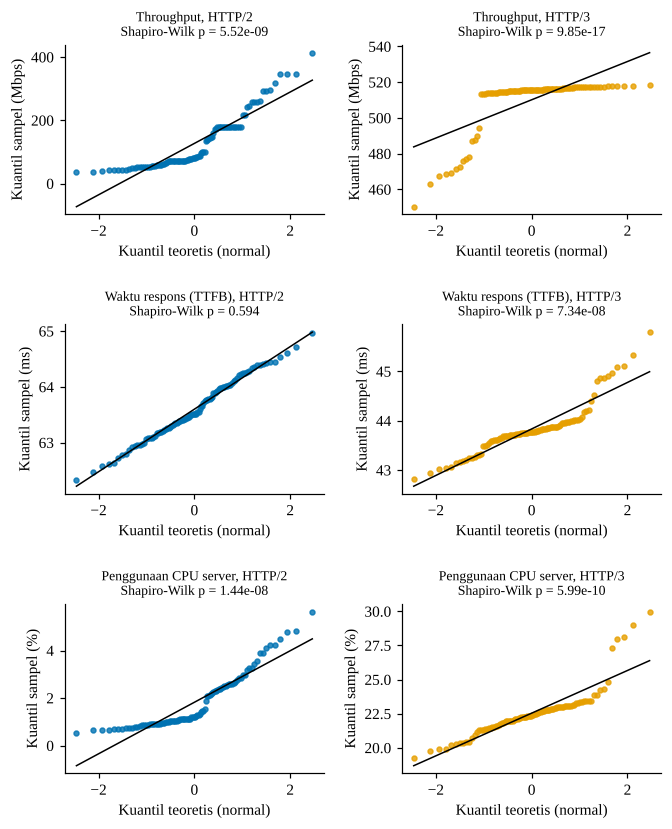

In [12]:
# ---- Gambar 4.5: Q-Q plot 3 variabel x 2 protokol ----
fig, axs = plt.subplots(3, 2, figsize=(7, 8.6), gridspec_kw={"hspace": 0.65, "wspace": 0.3})
for i, (v, (lab, sat)) in enumerate(VARS.items()):
    for j, p in enumerate(PROTO):
        x = df.loc[df["protokol"] == p, v].to_numpy()
        (osm, osr), (slope, intercept, r) = stats.probplot(x, dist="norm")
        ax = axs[i, j]
        ax.plot(osm, osr, "o", ms=3.2, color=WARNA[p], alpha=0.8)
        ax.plot(osm, slope*osm + intercept, "-", color="black", lw=1)
        pv = normal[(normal["kode"] == v) & (normal["Protokol"] == p)]["Nilai-p"].iloc[0]
        ax.set_title(f"{lab}, {p}\nShapiro-Wilk p = {pv:.3g}", fontsize=9)
        ax.set_xlabel("Kuantil teoretis (normal)"); ax.set_ylabel(f"Kuantil sampel ({sat.split(' ')[0]})")
simpan(fig, "gambar_4_5_qqplot")

## 4. Uji beda dua kelompok (Bab 4.4, Tabel 4.6)

H0: tidak ada perbedaan HTTP/2 dan HTTP/3; H1: ada perbedaan (dua arah, alpha 0,05). Tiga variabel diuji dengan data yang sama, jadi nilai-p dikoreksi **Holm** (kontrol *family-wise error rate*). Uji Welch tidak mengasumsikan ragam sama; Mann-Whitney U memakai versi dua arah dengan koreksi kontinuitas dan nilai-p asimtotik (ada banyak nilai kembar).

In [13]:
def uji_dua_kelompok(a, b, jenis):
    """a = HTTP/2, b = HTTP/3. Mengembalikan (nama statistik, nilai statistik, p)."""
    if jenis == "Welch":
        r = stats.ttest_ind(b, a, equal_var=False)
        return "t", r.statistic, r.pvalue
    r = stats.mannwhitneyu(b, a, alternative="two-sided", method="asymptotic")
    return "U", r.statistic, r.pvalue

rows = []
for v, (lab, sat) in VARS.items():
    a = df.loc[df["protokol"] == "HTTP/2", v].to_numpy(); b = df.loc[df["protokol"] == "HTTP/3", v].to_numpy()
    nama, st, pv = uji_dua_kelompok(a, b, PILIHAN[v])
    rows.append({"Variabel": lab, "kode": v, "Uji yang dipakai": PILIHAN[v],
                 "Statistik": f"{nama} = {st:.3f}", "stat_nilai": st, "Nilai-p mentah": pv})
uji = pd.DataFrame(rows)
uji["Nilai-p (Holm)"] = holm(uji["Nilai-p mentah"])
uji["Keputusan H0"] = np.where(uji["Nilai-p (Holm)"] < ALPHA, "ditolak", "gagal ditolak")
uji.drop(columns=["kode", "stat_nilai"]).to_csv("tabel/tabel_4_6_uji_beda.csv", index=False)
uji.drop(columns=["kode", "stat_nilai"])

,Variabel,Uji yang dipakai,Statistik,Nilai-p mentah,Nilai-p (Holm),Keputusan H0
0,Throughput,Mann-Whitney U,U = 10000.000,2.561999e-34,7.683834e-34,ditolak
1,Waktu respons (TTFB),Mann-Whitney U,U = 0.000,2.561278e-34,7.683834e-34,ditolak
2,Penggunaan CPU server,Mann-Whitney U,U = 10000.000,2.561711e-34,7.683834e-34,ditolak


In [14]:
# Untuk transparansi, jalankan KEDUA uji pada semua variabel (bukan untuk memilih ulang, hanya melihat apakah kesimpulan sama)
rows = []
for v, (lab, sat) in VARS.items():
    a = df.loc[df["protokol"] == "HTTP/2", v].to_numpy(); b = df.loc[df["protokol"] == "HTTP/3", v].to_numpy()
    tw = stats.ttest_ind(b, a, equal_var=False); mw = stats.mannwhitneyu(b, a, alternative="two-sided")
    bf = stats.levene(a, b, center="median")
    rows.append((lab, tw.statistic, tw.pvalue, mw.statistic, mw.pvalue, bf.statistic, bf.pvalue))
pd.DataFrame(rows, columns=["Variabel", "t Welch", "p Welch", "U MW", "p MW", "F Brown-Forsythe", "p BF"]).to_csv(
    "tabel/pendukung_kedua_uji_dan_kesamaan_ragam.csv", index=False)
pd.DataFrame(rows, columns=["Variabel", "t Welch", "p Welch", "U MW", "p MW", "F Brown-Forsythe", "p BF"])

,Variabel,t Welch,p Welch,U MW,p MW,F Brown-Forsythe,p BF
0,Throughput,43.365881,9.466909e-69,10000.0,2.561999e-34,62.991157,1.510267e-13
1,Waktu respons (TTFB),-264.901214,3.626985e-252,0.0,2.561278e-34,7.816849,5.685988e-03
2,Penggunaan CPU server,100.067628,3.022082e-155,10000.0,2.561711e-34,1.191452,2.763633e-01


## 5. Besar dan arah selisih (Bab 4.5, Tabel 4.7)

Selisih dihitung **HTTP/3 dikurangi HTTP/2**. Δ% = (rata-rata H3 − rata-rata H2) / rata-rata H2 × 100 (Persamaan 2-8). Ukuran efek: Cohen's d (selisih rata-rata dibagi simpangan baku gabungan) untuk variabel yang diuji Welch, Cliff's delta untuk variabel yang diuji Mann-Whitney U. Selang kepercayaan 95% memakai bootstrap persentil (resampling dalam tiap kelompok, 10.000 kali) pada selisih yang sesuai dengan ukuran utamanya: selisih **median** untuk variabel Mann-Whitney U dan selisih **rata-rata** untuk variabel Welch.

In [15]:
def cohen_d(a, b):                       # b - a, pooled SD
    na, nb = len(a), len(b)
    sp = np.sqrt(((na-1)*np.var(a, ddof=1) + (nb-1)*np.var(b, ddof=1)) / (na+nb-2))
    return (np.mean(b) - np.mean(a)) / sp

def cliffs_delta(a, b):                  # P(b > a) - P(b < a)
    A = np.asarray(a)[:, None]; B = np.asarray(b)[None, :]
    return (np.sum(B > A) - np.sum(B < A)) / (len(a) * len(b))

def kategori_d(d):
    d = abs(d); return "diabaikan" if d < 0.2 else "kecil" if d < 0.5 else "sedang" if d < 0.8 else "besar"
def kategori_cliff(d):
    d = abs(d); return "diabaikan" if d < 0.147 else "kecil" if d < 0.33 else "sedang" if d < 0.474 else "besar"

def boot_ci(a, b, stat, n=N_BOOT):
    sel = np.empty(n)
    for i in range(n):
        sel[i] = stat(rng.choice(b, len(b))) - stat(rng.choice(a, len(a)))
    return np.percentile(sel, [2.5, 97.5])

rows = []
for v, (lab, sat) in VARS.items():
    a = df.loc[df["protokol"] == "HTTP/2", v].to_numpy(); b = df.loc[df["protokol"] == "HTTP/3", v].to_numpy()
    sel_med = np.median(b) - np.median(a); sel_mean = b.mean() - a.mean()
    dpct = sel_mean / a.mean() * 100
    if PILIHAN[v] == "Welch":
        es_nama, es = "Cohen's d", cohen_d(a, b); kat = kategori_d(es)
        ci = boot_ci(a, b, np.mean); ci_ket = "selisih rata-rata"
    else:
        es_nama, es = "Cliff's delta", cliffs_delta(a, b); kat = kategori_cliff(es)
        ci = boot_ci(a, b, np.median); ci_ket = "selisih median"
    # CI bootstrap kedua ukuran, disimpan sebagai pendukung
    ci_med = boot_ci(a, b, np.median); ci_mean = boot_ci(a, b, np.mean)
    rows.append({"Variabel": lab, "kode": v, "Satuan": sat,
                 "Median H2": np.median(a), "Median H3": np.median(b),
                 "Selisih median (H3-H2)": sel_med, "Selisih rata-rata (H3-H2)": sel_mean, "Delta % rata-rata": dpct,
                 "Delta % median": sel_med / np.median(a) * 100,
                 "Ukuran efek": es_nama, "Nilai efek": es, "Interpretasi efek": kat,
                 "CI95 bawah": ci[0], "CI95 atas": ci[1], "CI untuk": ci_ket,
                 "CI median bawah": ci_med[0], "CI median atas": ci_med[1],
                 "CI rata-rata bawah": ci_mean[0], "CI rata-rata atas": ci_mean[1],
                 "Cohen d (pendukung)": cohen_d(a, b), "Cliff delta (pendukung)": cliffs_delta(a, b)})
efek = pd.DataFrame(rows)
efek.drop(columns="kode").to_csv("tabel/tabel_4_7_besar_efek.csv", index=False)
efek.drop(columns=["kode"]).round(3).T

,0,1,2
Variabel,Throughput,Waktu respons (TTFB),Penggunaan CPU server
Satuan,Mbps,ms,% dari satu core
Median H2,79.493,63.518,1.22
Median H3,515.637,43.774,22.382
Selisih median (H3-H2),436.144,-19.744,21.162
Selisih rata-rata (H3-H2),383.243,-19.766,20.715
Delta % rata-rata,302.009,-31.08,1136.706
Delta % median,548.656,-31.084,1734.631
Ukuran efek,Cliff's delta,Cliff's delta,Cliff's delta
Nilai efek,1.0,-1.0,1.0


In [16]:
# ---- Sensitivitas terhadap pencilan 1,5 x IQR (Bab 3.9.1): analisis ulang tanpa pencilan ----
rows = []
for v, (lab, sat) in VARS.items():
    ok = ~df[f"pencilan_{v}"]
    a = df.loc[(df["protokol"] == "HTTP/2") & ok, v].to_numpy(); b = df.loc[(df["protokol"] == "HTTP/3") & ok, v].to_numpy()
    a0 = df.loc[df["protokol"] == "HTTP/2", v].to_numpy(); b0 = df.loc[df["protokol"] == "HTTP/3", v].to_numpy()
    mw = stats.mannwhitneyu(b, a, alternative="two-sided"); tw = stats.ttest_ind(b, a, equal_var=False)
    rows.append({"Variabel": lab, "n H2 (tanpa pencilan)": len(a), "n H3 (tanpa pencilan)": len(b),
                 "Selisih median penuh": np.median(b0) - np.median(a0), "Selisih median tanpa pencilan": np.median(b) - np.median(a),
                 "p MW penuh": stats.mannwhitneyu(b0, a0).pvalue, "p MW tanpa pencilan": mw.pvalue,
                 "p Welch tanpa pencilan": tw.pvalue,
                 "Cliff delta penuh": cliffs_delta(a0, b0), "Cliff delta tanpa pencilan": cliffs_delta(a, b)})
sens = pd.DataFrame(rows)
sens.to_csv("tabel/pendukung_sensitivitas_pencilan.csv", index=False)
sens.round(4).T

,0,1,2
Variabel,Throughput,Waktu respons (TTFB),Penggunaan CPU server
n H2 (tanpa pencilan),99,100,99
n H3 (tanpa pencilan),86,84,93
Selisih median penuh,436.1435,-19.744,21.1625
Selisih median tanpa pencilan,436.3525,-19.751,21.139
p MW penuh,0.0,0.0,0.0
p MW tanpa pencilan,0.0,0.0,0.0
p Welch tanpa pencilan,0.0,0.0,0.0
Cliff delta penuh,1.0,-1.0,1.0
Cliff delta tanpa pencilan,1.0,-1.0,1.0


## 6. Analisis pendukung pembahasan (Bab 4.6)

Bagian ini **eksploratif**: dipakai untuk menafsirkan hasil, bukan untuk uji hipotesis utama. Ada dua alasan.

1. **Persentase CPU bergantung pada durasi.** `cpu_persen` = waktu CPU Caddy dibagi waktu total unduhan. Unduhan yang lebih lama membagi kerja CPU ke waktu yang lebih panjang sehingga persentasenya kecil, walau total kerjanya belum tentu kecil. Kita bisa memulihkan **total waktu CPU per unduhan** dari data yang ada:

   `waktu_total = TTFB + (bit berkas / throughput)` dan `waktu_CPU = cpu_persen/100 x waktu_total`.

2. **Sebaran throughput HTTP/2 lebar dan tampak "berundak".** Kita periksa bentuknya.

In [17]:
# ---- Variabel turunan (EKSPLORATIF; dihitung dari kolom asli, bukan kolom baru hasil pengukuran) ----
df["durasi_transfer_ms"] = BYTES_FILE * 8 / (df["throughput"] * 1e6) * 1000
df["waktu_total_ms"]     = df["durasi_transfer_ms"] + df["waktu_respons"]
df["cpu_ms"]             = df["cpu_persen"] / 100 * df["waktu_total_ms"]

turunan = {"waktu_total_ms": ("Waktu total unduhan", "ms"), "cpu_ms": ("Total waktu CPU per unduhan", "ms")}
rows = []
for v, (lab, sat) in turunan.items():
    a = df.loc[df["protokol"] == "HTTP/2", v].to_numpy(); b = df.loc[df["protokol"] == "HTTP/3", v].to_numpy()
    mw = stats.mannwhitneyu(b, a, alternative="two-sided")
    rows.append({"Ukuran": f"{lab} ({sat})",
                 "Median H2": np.median(a), "IQR H2": np.subtract(*np.percentile(a, [75, 25])),
                 "Median H3": np.median(b), "IQR H3": np.subtract(*np.percentile(b, [75, 25])),
                 "Selisih median (H3-H2)": np.median(b) - np.median(a),
                 "Rasio median H3/H2": np.median(b) / np.median(a),
                 "Cliff delta": cliffs_delta(a, b), "p MW (mentah, eksploratif)": mw.pvalue})
tabel48 = pd.DataFrame(rows)
tabel48.to_csv("tabel/tabel_4_8_durasi_dan_cpu_per_unduhan.csv", index=False)
tabel48.round(3)

,Ukuran,Median H2,IQR H2,Median H3,IQR H3,Selisih median (H3-H2),Rasio median H3/H2,Cliff delta,"p MW (mentah, eksploratif)"
0,Waktu total unduhan (ms),1118.677,916.530,206.510,0.848,-912.167,0.185,-1.0,0.0
1,Total waktu CPU per unduhan (ms),13.448,1.343,46.677,2.246,33.229,3.471,1.0,0.0


In [18]:
# ---- Perkiraan teoretis TTFB dari Bab 2.1.5 vs hasil teramati ----
RTT = 20.0   # ms (netem 10 ms per arah)
a = df.loc[df["protokol"] == "HTTP/2", "waktu_respons"]; b = df.loc[df["protokol"] == "HTTP/3", "waktu_respons"]
tabel49 = pd.DataFrame({
    "Ukuran": ["Perkiraan teoretis (ms)", "Median teramati (ms)", "Selisih teramati - teoretis (ms)"],
    "HTTP/2": [3*RTT, a.median(), a.median() - 3*RTT],
    "HTTP/3": [2*RTT, b.median(), b.median() - 2*RTT]})
tabel49.to_csv("tabel/tabel_4_9_ttfb_teoretis_vs_teramati.csv", index=False)
print("Selisih median TTFB teramati (H2 - H3):", round(a.median() - b.median(), 3), "ms  (perkiraan teoretis = 1 RTT = 20 ms)")
tabel49.round(3)

Selisih median TTFB teramati (H2 - H3): 19.744 ms  (perkiraan teoretis = 1 RTT = 20 ms)


,Ukuran,HTTP/2,HTTP/3
0,Perkiraan teoretis (ms),60.000,40.000
1,Median teramati (ms),63.518,43.774
2,Selisih teramati - teoretis (ms),3.517,3.773


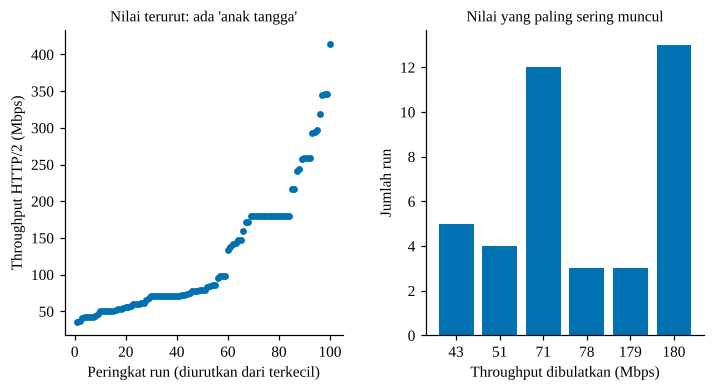

Nilai paling sering (dibulatkan 1 Mbps):
180.0    13
71.0     12
43.0      5
51.0      4
78.0      3
179.0     3
36.0      2
50.0      2


In [19]:
# ---- Gambar 4.6: sebaran throughput HTTP/2 yang berundak ----
h2 = df.loc[df["protokol"] == "HTTP/2", "throughput"].sort_values().to_numpy()
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7.5, 3.6), gridspec_kw={"wspace": 0.3})
ax1.plot(np.arange(1, len(h2)+1), h2, "o", ms=3.5, color=WARNA["HTTP/2"])
ax1.set_xlabel("Peringkat run (diurutkan dari terkecil)"); ax1.set_ylabel("Throughput HTTP/2 (Mbps)")
ax1.set_title("Nilai terurut: ada 'anak tangga'", fontsize=10)
# frekuensi nilai yang hampir sama (dibulatkan ke 1 Mbps)
vc = pd.Series(np.round(h2)).value_counts().head(6).sort_index()
ax2.bar(vc.index.astype(int).astype(str), vc.values, color=WARNA["HTTP/2"])
ax2.set_xlabel("Throughput dibulatkan (Mbps)"); ax2.set_ylabel("Jumlah run")
ax2.set_title("Nilai yang paling sering muncul", fontsize=10)
simpan(fig, "gambar_4_6_tingkat_throughput_h2")
print("Nilai paling sering (dibulatkan 1 Mbps):"); print(pd.Series(np.round(h2)).value_counts().head(8).to_string())

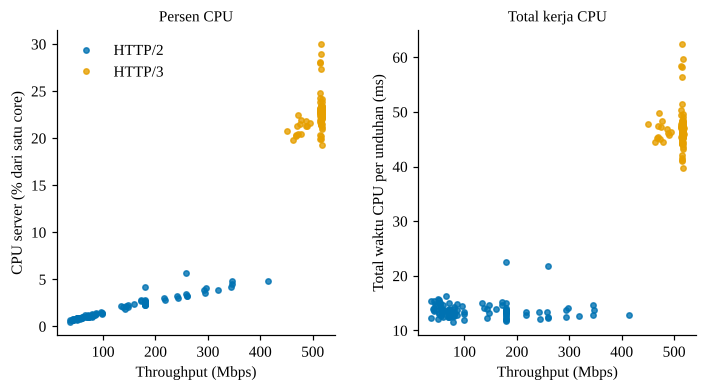

,Protokol,Variabel,rho Spearman dengan throughput,nilai-p
0,HTTP/2,cpu_persen,0.9735,0.0000
1,HTTP/2,cpu_ms,-0.2277,0.0227
2,HTTP/3,cpu_persen,0.2239,0.0251
3,HTTP/3,cpu_ms,-0.0667,0.5100


In [20]:
# ---- Gambar 4.7: hubungan throughput dan CPU% (mengapa persen CPU harus dibaca bersama durasi) ----
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7.5, 3.6), gridspec_kw={"wspace": 0.3})
for p in PROTO:
    g = df[df["protokol"] == p]
    ax1.plot(g["throughput"], g["cpu_persen"], "o", ms=3.5, color=WARNA[p], alpha=0.8, label=p)
    ax2.plot(g["throughput"], g["cpu_ms"], "o", ms=3.5, color=WARNA[p], alpha=0.8, label=p)
ax1.set_xlabel("Throughput (Mbps)"); ax1.set_ylabel("CPU server (% dari satu core)"); ax1.set_title("Persen CPU", fontsize=10)
ax2.set_xlabel("Throughput (Mbps)"); ax2.set_ylabel("Total waktu CPU per unduhan (ms)"); ax2.set_title("Total kerja CPU", fontsize=10)
ax1.legend(frameon=False)
simpan(fig, "gambar_4_7_cpu_vs_throughput")

rows = []
for p in PROTO:
    g = df[df["protokol"] == p]
    for v in ["cpu_persen", "cpu_ms"]:
        r = stats.spearmanr(g["throughput"], g[v]); rows.append((p, v, r.statistic, r.pvalue))
kor = pd.DataFrame(rows, columns=["Protokol", "Variabel", "rho Spearman dengan throughput", "nilai-p"])
kor.to_csv("tabel/pendukung_korelasi_throughput_cpu.csv", index=False)
kor.round(4)

In [21]:
# ---- Ringkasan angka kunci (dipakai untuk menulis Bab 4) ----
ringkas = {
    "n": {p: int((df['protokol'] == p).sum()) for p in PROTO},
    "pilihan_uji": PILIHAN,
}
print(json.dumps(ringkas, indent=2, ensure_ascii=False))
print("\nSemua tabel tersimpan di folder tabel/, semua gambar di folder gambar/.")

{
  "n": {
    "HTTP/2": 100,
    "HTTP/3": 100
  },
  "pilihan_uji": {
    "throughput": "Mann-Whitney U",
    "waktu_respons": "Mann-Whitney U",
    "cpu_persen": "Mann-Whitney U"
  }
}

Semua tabel tersimpan di folder tabel/, semua gambar di folder gambar/.


## Catatan interpretasi (baca sebelum menulis kesimpulan)

* **Statistik dan arti praktis bukan hal yang sama.** Nilai-p yang sangat kecil dengan n = 100 per kelompok hampir pasti terjadi bila selisihnya sebesar ini; yang menentukan arti praktis adalah ukuran efek dan selang kepercayaan.
* **Throughput HTTP/3 tampak mendekati batas atas yang sempit.** Sebabnya belum dapat dipastikan dari data ini (bisa karena batas kerja *user space* pada klien atau server, bisa karena dinamika kendali kemacetan Reno pada tundaan 20 ms). Jangan menulis sebab pasti di laporan; tulis sebagai dugaan yang perlu diuji.
* **Perbedaan algoritma kendali kemacetan (CUBIC pada TCP, Reno pada quic-go v0.59.1) adalah variabel pengganggu** yang tidak dapat dipisahkan dari perbedaan protokol pada rancangan ini (lihat Bab 3.10 dan Bab 4.6.6).
* Semua angka berasal dari **satu laptop, satu sesi, jaringan emulasi**; bukan dari server kampus.